# Blasius Boundary Layer Solution

In [2]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format='retina' # hig-res plots for a Retina display

The Blasius boundary layer equation is a similar solution that reduces the governing 2D PDE for laminar boundary layer flow down to the following 3rd order ODE:

\begin{align}
f''' + \frac{1}{2}ff'' = 0
\end{align}

where $f=f(\eta)$. The velocity distrubution along the similarity variable, $\eta$, can be found from $u(\eta)=U_o f'$, where $U_o$ is the free stream velocity. The equation above can easily be transformed into a system of 1st-order ODEs,

\begin{align}
f' &= g \\
g' &= h \\
h' &= -\frac{1}{2}fh \\
\end{align}

Note that $g=f'$, $h=f''$, and that the velocity profile is obtained from $g$. The three boundary conditions for the problem are

\begin{align}
f(\eta=0) &=  0\\
f'(\eta=0) &= 0 \\
f'(\eta \rightarrow \infty) &\rightarrow 1 \\
\end{align}

Note that $f'(\eta \rightarrow \infty) \rightarrow 1$ might be difficult to enforce and that no initial condition is givne for $f''(\eta=0)=h(\eta=0)$. If there as a value for $h(\eta=0)$, then we could proceed as we would with an initial value problem. The procedure we will use here is called a "shooting" method. To carry it out, we will (1) assume a value for $h(\eta=0)$, (2) use 4th-order Runge-Kutta to solve for $f$, $g$, and $h$. We'll then check the value of $g$ at a large $\eta$ value (say 10) to see if $g(\eta\rightarrow\infty)\rightarrow 1$. If it doesn't, then we'll need to update the value of $h(\eta=0)$ until $g(\eta\rightarrow\infty)\rightarrow 1$. We'll start out the calculations with $h(\eta=0)=1$.

## 1st pass using the assumed value for $h(\eta=0)$

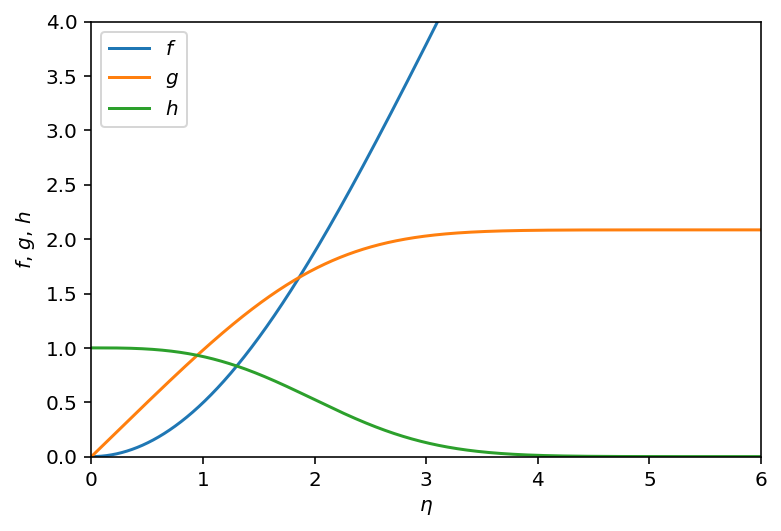

In [3]:
# --- User input ------------

# define the functions dy/dx = f(x,y)
def f(eta,y):
    return np.array([y[1],y[2],-0.5*y[0]*y[2]])

# define the number of points and the start and stop locations
start = 0
stop = 10     # eta value to stop at 
delta = 0.001  # Delta eta value


# initial values
f_0 = 0
g_0 = 0
h_0 = 1 # just a guess at this point

# --- Calculations ------------

# setup the x and y arrays
eta = np.arange(start,stop,delta)
N = len(eta)
y = np.zeros(shape=(3,N))
y[:,0]=[f_0,g_0,h_0]

# 4th Order Runge Kutta loop 
for i in range(0,N-1):
    K1 = f(eta[i]          , y[:,i]             )
    K2 = f(eta[i]+0.5*delta, y[:,i]+0.5*delta*K1)
    K3 = f(eta[i]+0.5*delta, y[:,i]+0.5*delta*K2)
    K4 = f(eta[i]+    delta, y[:,i]+    delta*K3)
    y[:,i+1] = y[:,i]+(delta/6)*(K1+2*K2+2*K3+K4)
    
# --- plot the results ------------

fig, ax = plt.subplots()
ax.plot(eta,y[0,:], label='$f$')
ax.plot(eta,y[1,:], label='$g$')
ax.plot(eta,y[2,:], label='$h$')
ax.set_xlabel('$\eta$')
ax.set_ylabel('$f$, $g$, $h$')
ax.set_ylim(0,4)
ax.set_xlim(0,6)
plt.legend(loc=2);

In [4]:
# look at the values as eta get's very large... y[1] should go to 1 (this is f'=g(eta))
y[1,-1]

2.085409176437886

## Update the initial condition by trial and error
Before doing so, let's build a function

In [5]:
# put as a function to make it easier to iterate

def bbl(eta,y,f_0,g_0,h_0):
    y[:,0]=[f_0,g_0,h_0]

    # 4th Order Runge Kutta loop 
    for i in range(0,N-1):
        K1 = f(eta[i]          , y[:,i]             )
        K2 = f(eta[i]+0.5*delta, y[:,i]+0.5*delta*K1)
        K3 = f(eta[i]+0.5*delta, y[:,i]+0.5*delta*K2)
        K4 = f(eta[i]+    delta, y[:,i]+    delta*K3)
        y[:,i+1] = y[:,i]+(delta/6)*(K1+2*K2+2*K3+K4)
    return y

In [6]:
# try different values of ho (or f''(eta = 0))
h_0 = 1
bbl(eta,y,f_0,g_0,h_0)[1,-1]

2.085409176437886

## Write a iterative loop to converge on an appropriate initial value automatically

In [7]:
# user input ----------------------------

g_inf_target = 1   # target value of g out in the free stream
error_lim = 0.0001 # set the difference between solution and target value
ho1 = 0            # inital guess one
ho2 = 1            # initial guess two

# calculations ----------------------------

# define a difference function between the target and the solution

def dif(ho,g_inf_target):
    return bbl(eta,y,f_0,g_0,ho)[1,-1]-g_inf_target

# define the error as the absolute value of the difference

error = abs(dif(ho2,g_inf_target))

# iterate on the initial value of h until the solution for g in the free stream matches the target

while error > error_lim:
    diff1 = dif(ho1,g_inf_target) 
    diff2 = dif(ho2,g_inf_target)
    
    dho = -diff2*((ho2-ho1)/(diff2-diff1))
    
    ho1 = ho2
    ho2 = ho2 + dho
    error = abs(diff2)

print('the initial boundary condition for f''(eta=0)=h(eta=0)=',ho2)

the initial boundary condition for f(eta=0)=h(eta=0)= 0.3320572999753484


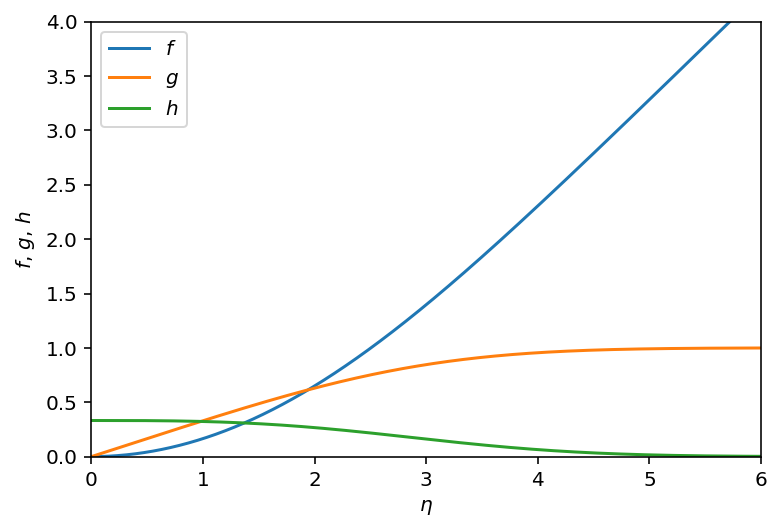

In [8]:
# solve with the correct boundary condition

y=bbl(eta,y,f_0,g_0,ho2)

# --- plot the results ------------

fig, ax = plt.subplots()
ax.plot(eta,y[0,:], label='$f$')
ax.plot(eta,y[1,:], label='$g$')
ax.plot(eta,y[2,:], label='$h$')
ax.set_xlabel('$\eta$')
ax.set_ylabel('$f$, $g$, $h$')
ax.set_ylim(0,4)
ax.set_xlim(0,6)
plt.legend(loc=2);

In [9]:
# look at the values as eta get's very large... y[1] should go to 1 (this is F=F(eta))
y[1,-1]

0.9999999252487135